In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# importing yeast count data

# 42 clean WT replicates
WT_yeast = pd.read_csv('WT_yeast.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast = pd.read_csv('Snf2_yeast.csv', index_col=0)

display(WT_yeast)
display(Snf2_yeast)

,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,15S_rRNA,2,12,31,8,21,11,2,3,7,...,0,49,9,4,11,12,1,22,12,4
1,21S_rRNA,20,76,101,99,128,74,36,32,57,...,10,274,49,30,72,58,21,159,107,70
2,HRA1,3,2,2,2,3,5,4,0,4,...,5,3,6,5,2,2,2,5,2,1
3,ICR1,75,123,107,157,98,245,119,120,119,...,85,177,137,118,113,81,142,94,187,106
4,LSR1,60,163,233,163,193,375,194,84,211,...,66,385,232,149,114,81,109,132,243,128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,0,1,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7122,tY(GUA)M1,0,0,1,1,1,1,0,0,1,...,0,1,1,0,1,0,0,0,1,0
7123,tY(GUA)M2,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,15S_rRNA,4,2,5,5,46,5,4,2,40,...,7,15,6,1,85,8,34,3,6,3
1,21S_rRNA,31,18,23,44,356,35,33,13,148,...,64,79,67,13,576,52,234,23,44,24
2,HRA1,5,1,3,1,2,1,4,4,0,...,5,5,0,2,0,1,2,2,0,1
3,ICR1,205,196,211,252,127,275,160,190,146,...,286,155,184,164,202,186,148,183,195,145
4,LSR1,210,103,159,260,298,303,96,132,263,...,250,195,153,57,742,227,227,117,224,136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1,0,0,0,0,0,1,0,0,...,1,1,0,0,0,0,0,2,1,1
7122,tY(GUA)M1,0,0,1,0,2,0,0,0,0,...,1,1,1,0,0,0,0,0,0,1
7123,tY(GUA)M2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,1,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0


In [13]:
# importing yeast count data >>> q-values
# from explore_clean_yeast_consistency.ipynb

# 42 clean WT replicates
WT_yeast_q = pd.read_csv('WT_yeast_q.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast_q = pd.read_csv('Snf2_yeast_q.csv', index_col=0)

display(WT_yeast_q)
display(Snf2_yeast_q)

,13_q,8_q,38_q,27_q,5_q,16_q,14_q,33_q,6_q,19_q,...,15_q,1_q,30_q,40_q,21_q,4_q,24_q,31_q,39_q,17_q
0,1.651220e-06,4.065404e-07,1.603579e-06,5.808502e-07,2.745867e-06,5.386557e-06,1.353193e-06,1.349760e-07,8.207817e-07,2.573225e-06,...,5.250010e-07,5.030082e-07,3.455352e-06,4.120753e-06,2.093998e-06,8.628760e-07,1.042284e-06,1.816573e-07,1.727728e-07,3.619449e-06
1,4.513335e-06,3.353958e-06,7.277780e-06,4.065951e-06,1.610077e-05,3.986052e-05,7.910972e-06,1.484737e-06,5.129886e-06,9.649594e-06,...,2.756255e-06,3.521057e-06,1.307024e-05,2.866611e-05,1.439624e-05,9.587511e-06,5.732564e-06,2.724860e-06,1.900501e-06,1.670515e-05
2,3.302440e-07,1.016351e-07,3.700566e-07,9.293603e-07,4.992486e-07,1.795519e-07,5.204587e-07,8.098563e-07,4.103909e-07,4.288709e-07,...,1.312503e-07,6.706775e-07,4.506981e-07,1.074979e-06,6.543744e-07,2.876253e-07,2.084569e-07,4.541433e-07,2.591592e-07,9.744670e-07
3,1.398033e-05,1.229785e-05,1.011488e-05,1.556678e-05,1.235640e-05,1.274819e-05,1.634240e-05,1.160794e-05,1.682602e-05,1.275891e-05,...,1.509378e-05,1.274287e-05,1.442234e-05,1.702050e-05,1.518149e-05,1.514827e-05,1.396661e-05,1.017281e-05,1.235325e-05,1.809724e-05
4,2.201627e-05,8.638984e-06,1.011488e-05,3.090123e-05,2.421356e-05,5.655885e-05,1.374011e-05,9.043395e-06,2.571783e-05,1.254447e-05,...,1.312503e-05,1.022783e-05,3.365212e-05,2.382870e-05,2.970860e-05,1.572352e-05,2.105414e-05,9.173695e-06,9.502503e-06,2.881638e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,1.100813e-07,1.016351e-07,1.233522e-07,1.161700e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,2.051954e-07,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07
7122,1.100813e-07,1.016351e-07,1.233522e-07,2.323401e-07,2.496243e-07,1.795519e-07,1.040917e-07,1.349760e-07,1.367970e-07,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,2.617497e-07,1.917502e-07,2.084569e-07,9.082867e-08,8.638639e-08,4.176287e-07
7123,1.100813e-07,1.016351e-07,1.233522e-07,2.323401e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,6.839848e-08,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07
7124,1.100813e-07,1.016351e-07,1.233522e-07,1.161700e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,6.839848e-08,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07


,11_q,23_q,5_q,27_q,43_q,33_q,13_q,24_q,31_q,28_q,...,40_q,7_q,21_q,32_q,26_q,15_q,10_q,22_q,19_q,2_q
0,6.755117e-07,9.171568e-07,6.827575e-06,4.152554e-06,7.991772e-07,1.127455e-06,9.497976e-07,1.205007e-06,8.953913e-07,7.889508e-07,...,1.014152e-06,6.136811e-07,1.215388e-06,4.463240e-07,9.023679e-07,5.007454e-06,8.074703e-07,7.894240e-06,2.203145e-06,3.450619e-07
1,3.242456e-06,7.642973e-06,5.186051e-05,2.366956e-05,5.137568e-06,3.883457e-06,4.748988e-06,7.832543e-06,5.148500e-06,6.048623e-06,...,5.972229e-06,4.173032e-06,5.401724e-06,3.459011e-06,7.863492e-06,3.848866e-05,6.560696e-06,3.114636e-05,9.337138e-06,2.185392e-06
2,4.053070e-07,1.019063e-07,4.358026e-07,2.768369e-07,1.141682e-07,2.505456e-07,2.374494e-07,6.025033e-07,3.357717e-07,6.574590e-07,...,2.253671e-07,6.136811e-07,1.350431e-07,3.347430e-07,2.578194e-07,2.945561e-07,4.037352e-07,4.305949e-07,6.294700e-07,2.300412e-07
3,2.202168e-05,2.201176e-05,1.859425e-05,1.716389e-05,2.237696e-05,1.828983e-05,1.733381e-05,1.491196e-05,1.712436e-05,1.354366e-05,...,2.107183e-05,1.976053e-05,2.133681e-05,1.305498e-05,2.797341e-05,2.002981e-05,1.937929e-05,1.901794e-05,1.982830e-05,2.265906e-05
4,2.418332e-05,1.569357e-05,4.343500e-05,3.681931e-05,2.568784e-05,2.117111e-05,7.242207e-06,1.551446e-05,2.126554e-05,1.078233e-05,...,2.569185e-05,1.190541e-05,2.376759e-05,9.707547e-06,1.740281e-05,4.320156e-05,1.594754e-05,3.695939e-05,2.706721e-05,1.196214e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,1.351023e-07,1.019063e-07,1.452675e-07,1.384185e-07,2.283363e-07,1.252728e-07,1.187247e-07,1.506258e-07,1.119239e-07,1.314918e-07,...,1.126836e-07,2.454724e-07,1.350431e-07,1.115810e-07,2.578194e-07,9.818537e-08,1.009338e-07,7.176581e-08,1.049117e-07,1.150206e-07
7122,1.351023e-07,2.038126e-07,4.358026e-07,1.384185e-07,1.141682e-07,2.505456e-07,1.187247e-07,1.506258e-07,1.119239e-07,2.629836e-07,...,1.126836e-07,1.227362e-07,4.051293e-07,1.115810e-07,1.289097e-07,1.963707e-07,1.009338e-07,1.435316e-07,1.049117e-07,1.150206e-07
7123,2.702047e-07,1.019063e-07,1.452675e-07,1.384185e-07,1.141682e-07,1.252728e-07,1.187247e-07,1.506258e-07,1.119239e-07,1.314918e-07,...,1.126836e-07,1.227362e-07,1.350431e-07,1.115810e-07,1.289097e-07,1.963707e-07,1.009338e-07,7.176581e-08,2.098233e-07,1.150206e-07
7124,1.351023e-07,1.019063e-07,1.452675e-07,1.384185e-07,1.141682e-07,1.252728e-07,1.187247e-07,1.506258e-07,2.238478e-07,1.314918e-07,...,1.126836e-07,1.227362e-07,1.350431e-07,1.115810e-07,1.289097e-07,9.818537e-08,1.009338e-07,7.176581e-08,1.049117e-07,2.300412e-07


In [14]:
# importing yeast count data >>> average q-values
# from explore_clean_yeast_consistency.ipynb

# 42 clean WT replicates
WT_yeast_avq = pd.read_csv('WT_yeast_avq.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast_avq = pd.read_csv('Snf2_yeast_avq.csv', index_col=0)

display(WT_yeast_avq)
display(Snf2_yeast_avq)

,genes,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,15S_rRNA,5.030082e-07,1.082671e-06,2.266838e-06,1.757651e-06,1.936241e-06,1.611843e-06,1.414441e-06,1.262933e-06,1.211224e-06,...,1.904640e-06,1.853748e-06,1.946728e-06,1.911901e-06,1.879292e-06,1.874652e-06,1.864698e-06,1.802844e-06,1.838121e-06,1.808986e-06
1,21S_rRNA,3.521057e-06,7.001270e-06,9.757261e-06,9.667083e-06,1.097203e-05,9.352440e-06,8.599160e-06,7.869044e-06,7.712282e-06,...,1.143895e-05,1.116937e-05,1.165616e-05,1.143130e-05,1.125617e-05,1.124791e-05,1.114460e-05,1.082007e-05,1.111147e-05,1.103367e-05
2,HRA1,6.706775e-07,4.330683e-07,3.942327e-07,3.254910e-07,3.356151e-07,3.373626e-07,3.536103e-07,3.053245e-07,3.213451e-07,...,3.409082e-07,3.498319e-07,3.457776e-07,3.543033e-07,3.621552e-07,3.608785e-07,3.579971e-07,3.515545e-07,3.605317e-07,3.538079e-07
3,ICR1,1.274287e-05,1.436343e-05,1.507940e-05,1.507023e-05,1.448308e-05,1.510635e-05,1.486771e-05,1.450291e-05,1.438637e-05,...,1.402170e-05,1.395360e-05,1.399016e-05,1.398161e-05,1.403270e-05,1.409661e-05,1.399302e-05,1.393298e-05,1.398095e-05,1.403248e-05
4,LSR1,1.022783e-05,1.616788e-05,2.252055e-05,2.018044e-05,2.098885e-05,2.226593e-05,2.221316e-05,2.034571e-05,2.072676e-05,...,2.320770e-05,2.282563e-05,2.321551e-05,2.321690e-05,2.314857e-05,2.302277e-05,2.269390e-05,2.223207e-05,2.225545e-05,2.218147e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1.676694e-07,1.443561e-07,9.855819e-08,6.509820e-08,5.163308e-08,7.496946e-08,6.429279e-08,5.551354e-08,4.943770e-08,...,1.852762e-08,1.803257e-08,1.728888e-08,1.671242e-08,1.631330e-08,1.596807e-08,1.556509e-08,1.502370e-08,1.477589e-08,1.426645e-08
7122,tY(GUA)M1,1.676694e-07,7.217804e-08,9.855819e-08,9.764730e-08,1.032662e-07,9.371182e-08,8.036599e-08,6.939192e-08,7.415655e-08,...,4.817182e-08,4.688468e-08,4.840887e-08,5.013727e-08,4.893989e-08,5.109783e-08,4.980829e-08,4.807583e-08,4.728285e-08,4.850592e-08
7123,tY(GUA)M2,1.676694e-07,7.217804e-08,9.855819e-08,6.509820e-08,5.163308e-08,3.748473e-08,4.821959e-08,4.163515e-08,3.707828e-08,...,1.482210e-08,1.442606e-08,1.383111e-08,1.336994e-08,1.305064e-08,1.277446e-08,1.245207e-08,1.201896e-08,1.182071e-08,1.141316e-08
7124,tY(GUA)O,1.676694e-07,7.217804e-08,4.927909e-08,3.254910e-08,2.581654e-08,1.874236e-08,3.214639e-08,2.775677e-08,2.471885e-08,...,1.111657e-08,1.081954e-08,1.037333e-08,1.336994e-08,1.305064e-08,1.277446e-08,1.245207e-08,1.201896e-08,1.182071e-08,1.141316e-08


,genes,1,2,3,4,5,6,7,8,9,...,34,35,36,37,38,39,40,41,42,43
0,15S_rRNA,4.888009e-07,3.699162e-07,4.332702e-07,4.431870e-07,1.392500e-06,1.178058e-06,1.093068e-06,9.750276e-07,1.354988e-06,...,2.247482e-06,2.162239e-06,2.153404e-06,2.107489e-06,2.068077e-06,2.252873e-06,2.219721e-06,2.264491e-06,2.219710e-06,2.184992e-06
1,21S_rRNA,3.128326e-06,2.642259e-06,2.635727e-06,3.050169e-06,1.045480e-05,8.800790e-06,8.213191e-06,7.299531e-06,8.343876e-06,...,1.195357e-05,1.158432e-05,1.153281e-05,1.139055e-05,1.119966e-05,1.252824e-05,1.236465e-05,1.273472e-05,1.249908e-05,1.232996e-05
2,HRA1,5.865611e-07,3.699162e-07,3.610585e-07,2.867680e-07,2.873412e-07,2.425414e-07,2.732670e-07,2.898731e-07,2.614890e-07,...,2.475201e-07,2.514231e-07,2.603689e-07,2.526609e-07,2.534122e-07,2.465408e-07,2.432571e-07,2.434937e-07,2.431111e-07,2.376114e-07
3,ICR1,2.013860e-05,2.124376e-05,2.213289e-05,2.255039e-05,2.192635e-05,2.195000e-05,2.166400e-05,2.130567e-05,2.095478e-05,...,1.977850e-05,1.973357e-05,1.970839e-05,1.967188e-05,1.975450e-05,1.979128e-05,1.981993e-05,1.979874e-05,1.982148e-05,1.987671e-05
4,LSR1,2.062740e-05,1.659338e-05,1.707807e-05,1.910918e-05,2.278837e-05,2.311074e-05,2.170954e-05,2.058099e-05,2.169170e-05,...,2.351111e-05,2.317493e-05,2.318508e-05,2.295350e-05,2.265855e-05,2.414683e-05,2.418197e-05,2.428173e-05,2.402572e-05,2.406074e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1.955204e-07,1.056903e-07,7.221170e-08,5.213964e-08,4.420634e-08,3.464878e-08,4.554450e-08,3.952815e-08,3.565759e-08,...,1.320107e-08,1.571395e-08,1.837898e-08,1.783489e-08,1.747671e-08,1.700282e-08,1.658571e-08,1.623291e-08,2.114009e-08,2.324459e-08
7122,tY(GUA)M1,9.776019e-08,5.284517e-08,7.221170e-08,5.213964e-08,8.841268e-08,6.929756e-08,6.072600e-08,5.270420e-08,4.754345e-08,...,4.950401e-08,5.028463e-08,5.207378e-08,5.350466e-08,5.243012e-08,5.100845e-08,4.975714e-08,4.869873e-08,4.756521e-08,4.648918e-08
7123,tY(GUA)M2,9.776019e-08,5.284517e-08,3.610585e-08,2.606982e-08,2.210317e-08,1.732439e-08,1.518150e-08,1.317605e-08,1.188586e-08,...,1.650134e-08,1.571395e-08,1.531582e-08,1.486241e-08,1.456392e-08,1.416901e-08,1.382143e-08,1.352743e-08,1.321256e-08,1.291366e-08
7124,tY(GUA)O,9.776019e-08,1.056903e-07,7.221170e-08,5.213964e-08,4.420634e-08,3.464878e-08,3.036300e-08,2.635210e-08,3.565759e-08,...,1.980160e-08,1.885673e-08,2.144214e-08,2.080737e-08,2.038949e-08,1.983662e-08,1.935000e-08,1.893840e-08,1.849758e-08,1.807913e-08


In [15]:
# importing results from differential gene expression anaylsis
RALL_bayexpress = pd.read_csv('RALL_bayexpress.csv', index_col=0)

display(RALL_bayexpress)

,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
0,15S_rRNA,-3.710645,0.274047,-107.138056,False,53.627445,True
1,21S_rRNA,-1.302642,0.147177,362.115507,True,1052.203968,True
2,HRA1,-5.206545,-0.564787,-240.338654,False,-258.581365,False
3,ICR1,76.746125,0.504048,-194.077441,False,-196.467262,False
4,LSR1,0.451012,0.120243,251.787125,True,478.066414,True
...,...,...,...,...,...,...,...
7121,tY(GUA)J2,-7.312143,0.861839,-270.299503,False,-281.214963,False
7122,tY(GUA)M1,-7.406574,0.022303,-262.736078,False,-275.253246,False
7123,tY(GUA)M2,-7.727890,0.183767,-271.177492,False,-284.863866,False
7124,tY(GUA)O,-7.622253,0.347266,-270.291196,False,-282.682788,False


In [19]:
# define function to get plots showing the package comparison numbers
# all the info from explore_clean_yeast.ipynb
# plus consistency tests
# PCN plots, 100 bootstrapping iterations

# Set global font size to 12
plt.rcParams.update({'font.size': 12})

def q_plot(genes):

    # Find the index of all genes
    igenes = [list(RALL_bayexpress.locus_name).index(gene) for gene in genes]
    
    # Some more numbers about the genes

    print('Read counts in WT across replicates:')
    display(WT_yeast.iloc[igenes])

    print('Read counts in Snf2 mutant across replicates:')
    display(Snf2_yeast.iloc[igenes])

    print('bayexpress results:')
    display(RALL_bayexpress.iloc[igenes])

    print('With:')
    print('BF_21 ... Bayes factor for differential gene expression analysis')
    print('FC ... inferred log_2 fold change')

    print('BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type')

    print('BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant')


    # printing q-plots
    for t in igenes:
        fig, ax = plt.subplots(dpi=300)

        ax.hist(WT_yeast_q.iloc[t], 10, density=False, histtype='step', color='#5D3A9B',
                alpha=0.4, orientation='horizontal')

        ax.hist(Snf2_yeast_q.iloc[t], 10, density=False, histtype='step', color='#E66100',
                alpha=0.4, orientation='horizontal')


        # scatter WT
        gene_WT_BF_k1 = str(RALL_bayexpress.loc[t].BF_k1_WT.round(3))
        ax.scatter(np.arange(1,len(WT_yeast_q.columns)+1), WT_yeast_q.iloc[t],
                
            c='#5D3A9B', s=30, 
            label=f'BF_k1 = {gene_WT_BF_k1}',
            alpha=0.95, edgecolors='none')
        
        # scatter Snf2
        gene_Snf2_BF_k1 = str(RALL_bayexpress.loc[t].BF_k1_Snf2.round(3))
        ax.scatter(np.arange(1,len(Snf2_yeast_q.columns)+1), Snf2_yeast_q.iloc[t],
                
            c='#E66100', s=30, 
            label=f'BF_k1 = {gene_Snf2_BF_k1}',
            alpha=0.95, edgecolors='none')
        
        ax.legend(loc='upper right')
        
        # average estimates WT
        series = WT_yeast_avq.iloc[t,1:]
        series.plot(color='#5D3A9B', alpha=0.3, linewidth=10)
        
        # average estimates Snf2
        series = Snf2_yeast_avq.iloc[t,1:]
        series.plot(color='#E66100', alpha=0.3, linewidth=10)
            
        gene = str(RALL_bayexpress.loc[t].locus_name)
        gene_BF_21 = str(RALL_bayexpress.loc[t].BF_21.round(3))
        gene_iFC = str(RALL_bayexpress.loc[t].FC.round(3))
        ax.set_title(f'{gene}: BF_21 = {gene_BF_21}, iFC = {gene_iFC}')

        # Use tex in labels
        ax.set_xticks(np.arange(1,44))
        ax.set_xticklabels('')

        # formatting y axis ticks
        plt.gca().ticklabel_format(axis='y', style='plain', useOffset=False)

        ax.set_xlabel('Replicates')
        ax.set_ylabel('q = (n+1) / (N+2)')

        plt.show()



In [20]:
# Let's find an example gene for every group in the venn diagramm
# In collaboration with package_comparison_RALL.ipynb

# DEG = 'statistically significant change' & | log2 fold change | > 1

# Which ones are positive in bayexpress but not the other 2?
# 138 genes
# YAL016C-B

# Which ones are positive in edgeR but not the other 2?
# 0 genes
# -

# Which ones are positive in DESeq2 but not the other 2?
# 50 genes
# YDL062W

# Which ones are positive in DESeq2 and edgeR but not bayexpress?
# 98 genes
# RPR1

# Which ones are positive in DESeq2 and bayexpress but not edgeR?
# 52 genes
# YAL063C-A

# Which ones are positive in edgeR and bayexpress but not DESeq2?
# 1 gene
# YGR161W-C

# Which ones are positive hits in all 3?
# 342 genes
# YAL061W

# Which ones are not DEG in all 3?
# 6445 genes
# 15S_rRNA

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
76,YAL016C-B,21,33,43,54,15,72,31,23,23,...,29,70,40,32,42,26,37,24,45,33


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
76,YAL016C-B,85,61,88,96,72,169,64,61,84,...,133,38,72,51,84,83,51,98,104,70


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
76,YAL016C-B,126.045252,1.06013,-197.181254,False,-173.052282,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


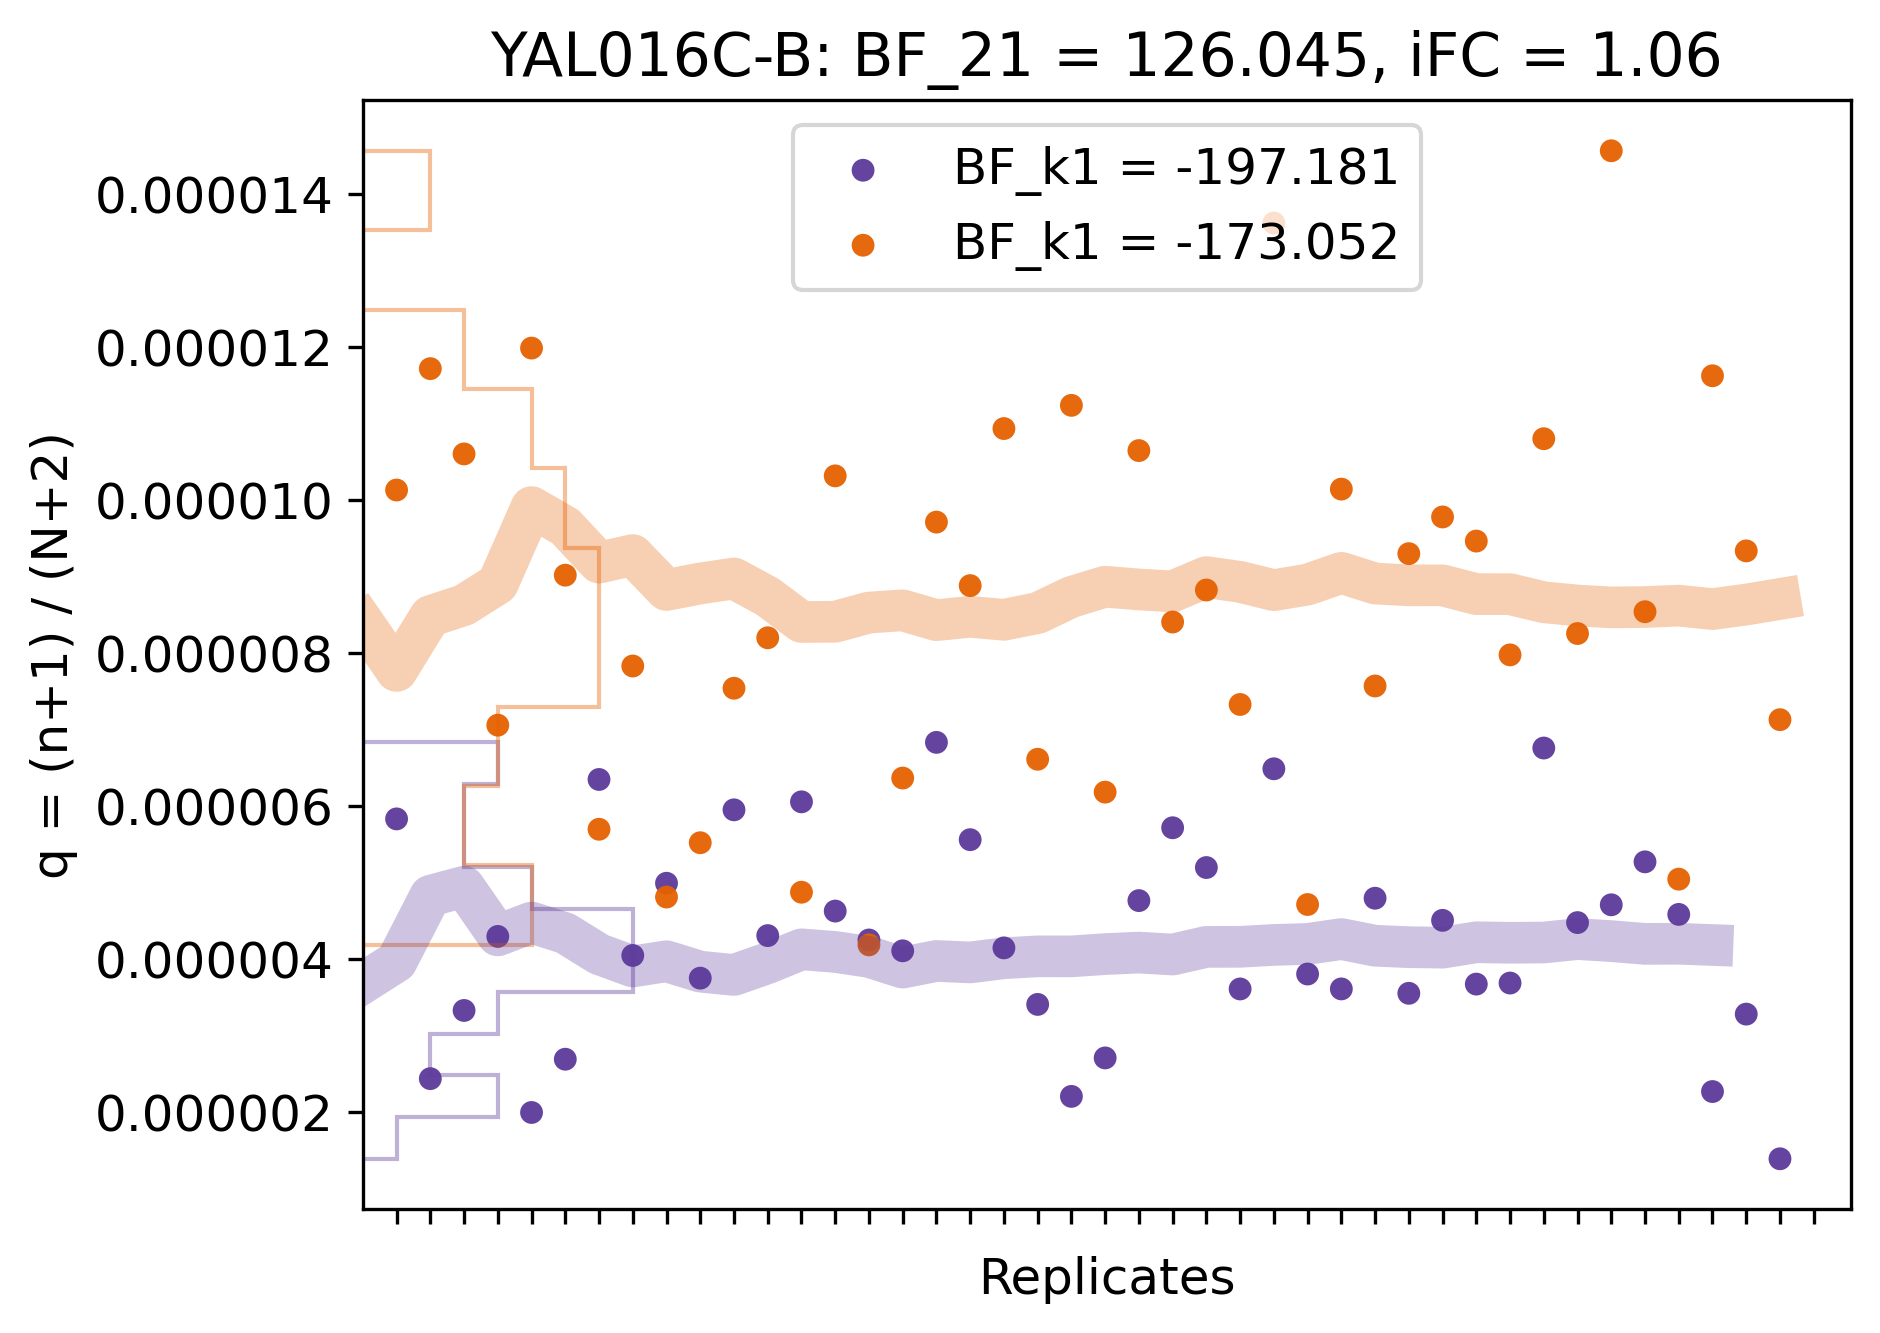

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
895,YDL062W,0,7,4,1,6,10,4,1,2,...,5,1,3,0,0,1,0,1,3,3


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
895,YDL062W,4,2,2,1,0,0,2,4,4,...,2,2,1,0,1,4,1,2,3,1


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
895,YDL062W,-3.484584,-0.86686,-238.308682,False,-262.370592,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


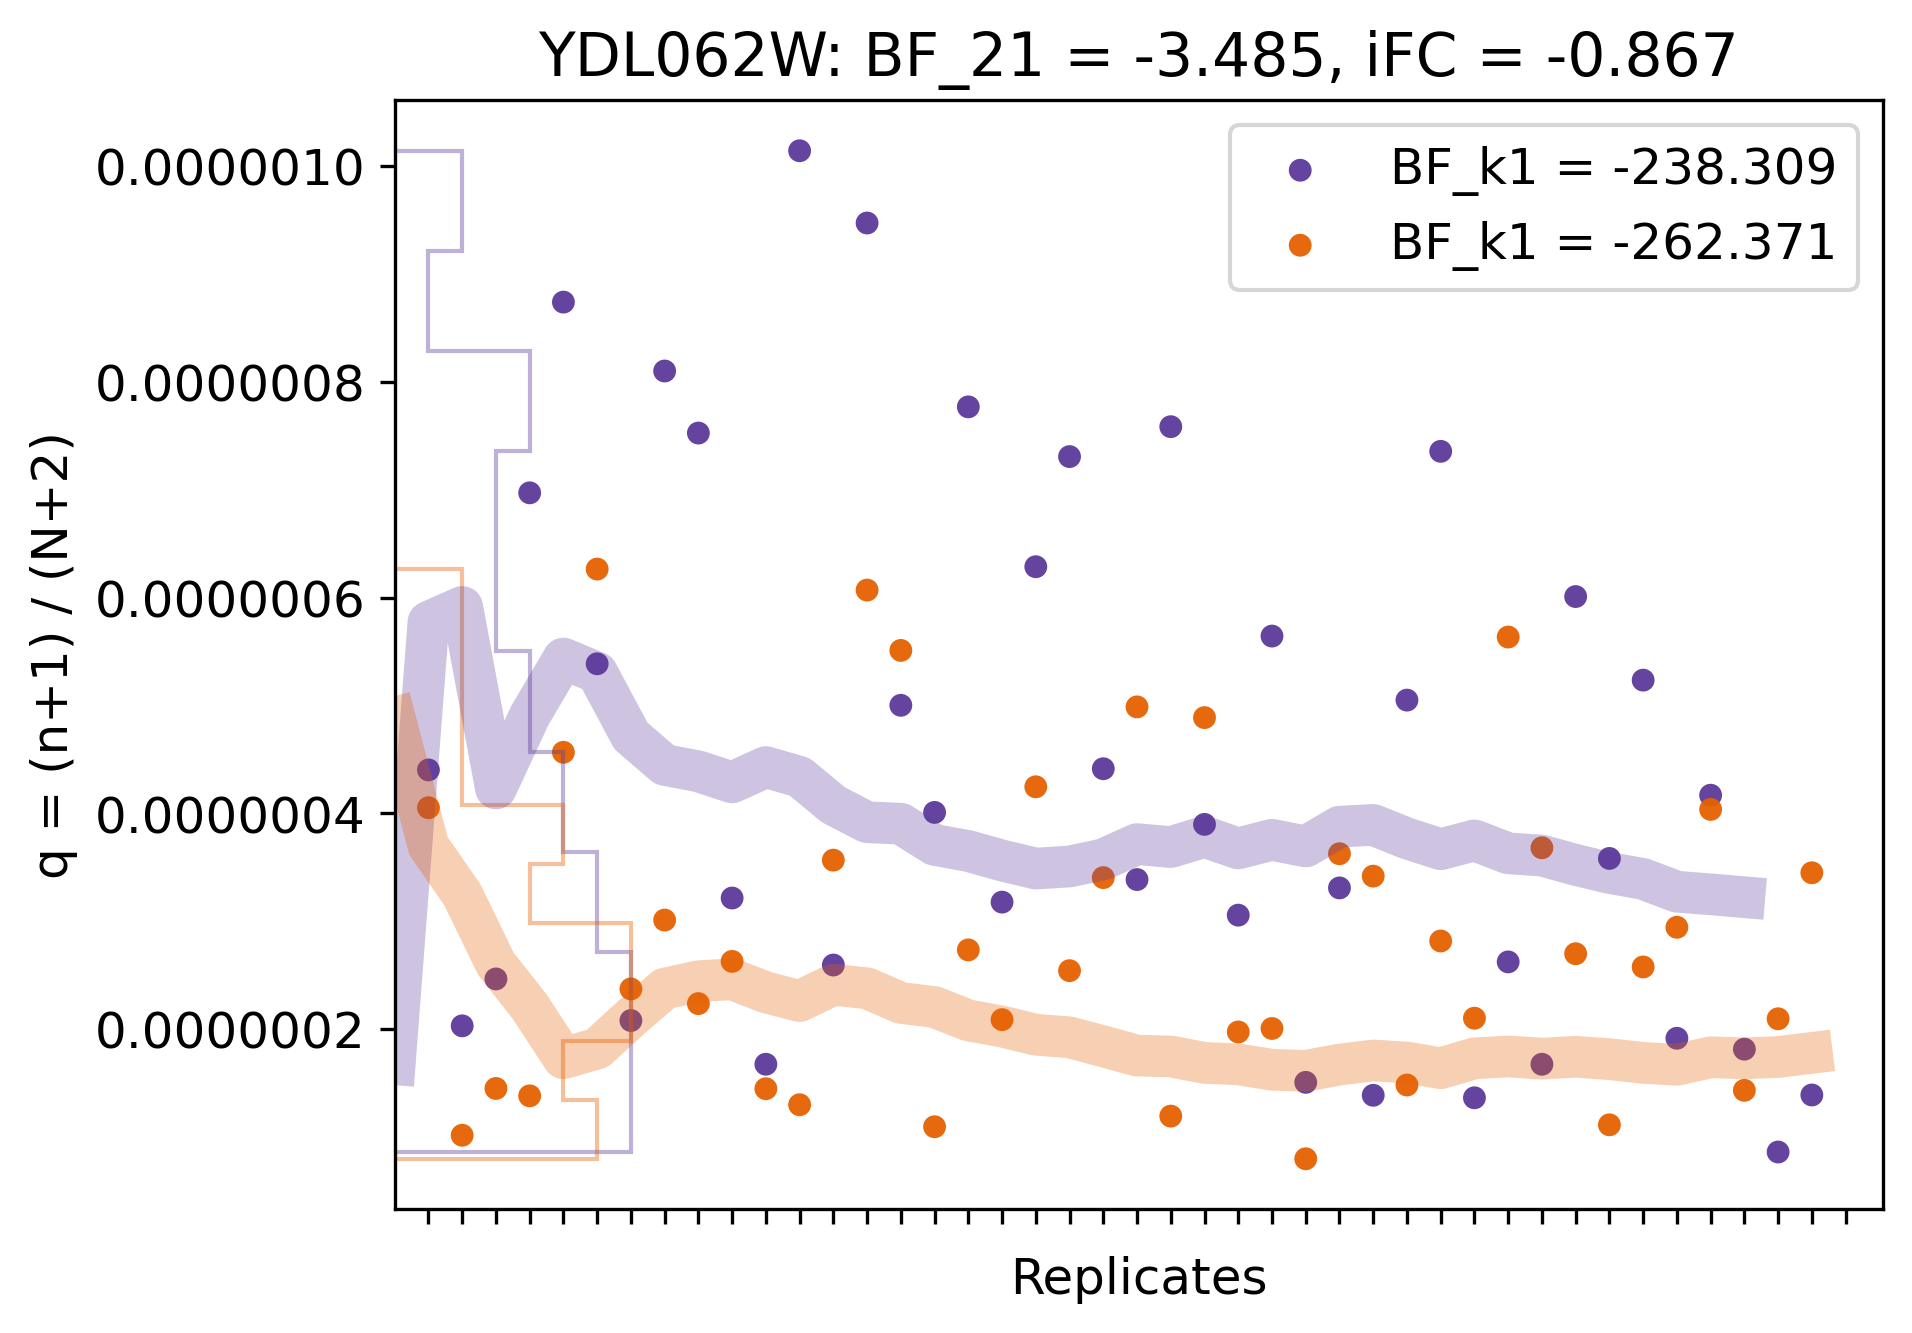

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
51,RPR1,31,42,51,93,79,83,80,48,145,...,39,82,60,38,43,45,53,33,97,70


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
51,RPR1,36,27,19,31,47,32,30,25,41,...,50,44,53,16,99,28,25,15,40,21


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
51,RPR1,102.505781,-0.973507,-29.530821,False,-163.63689,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


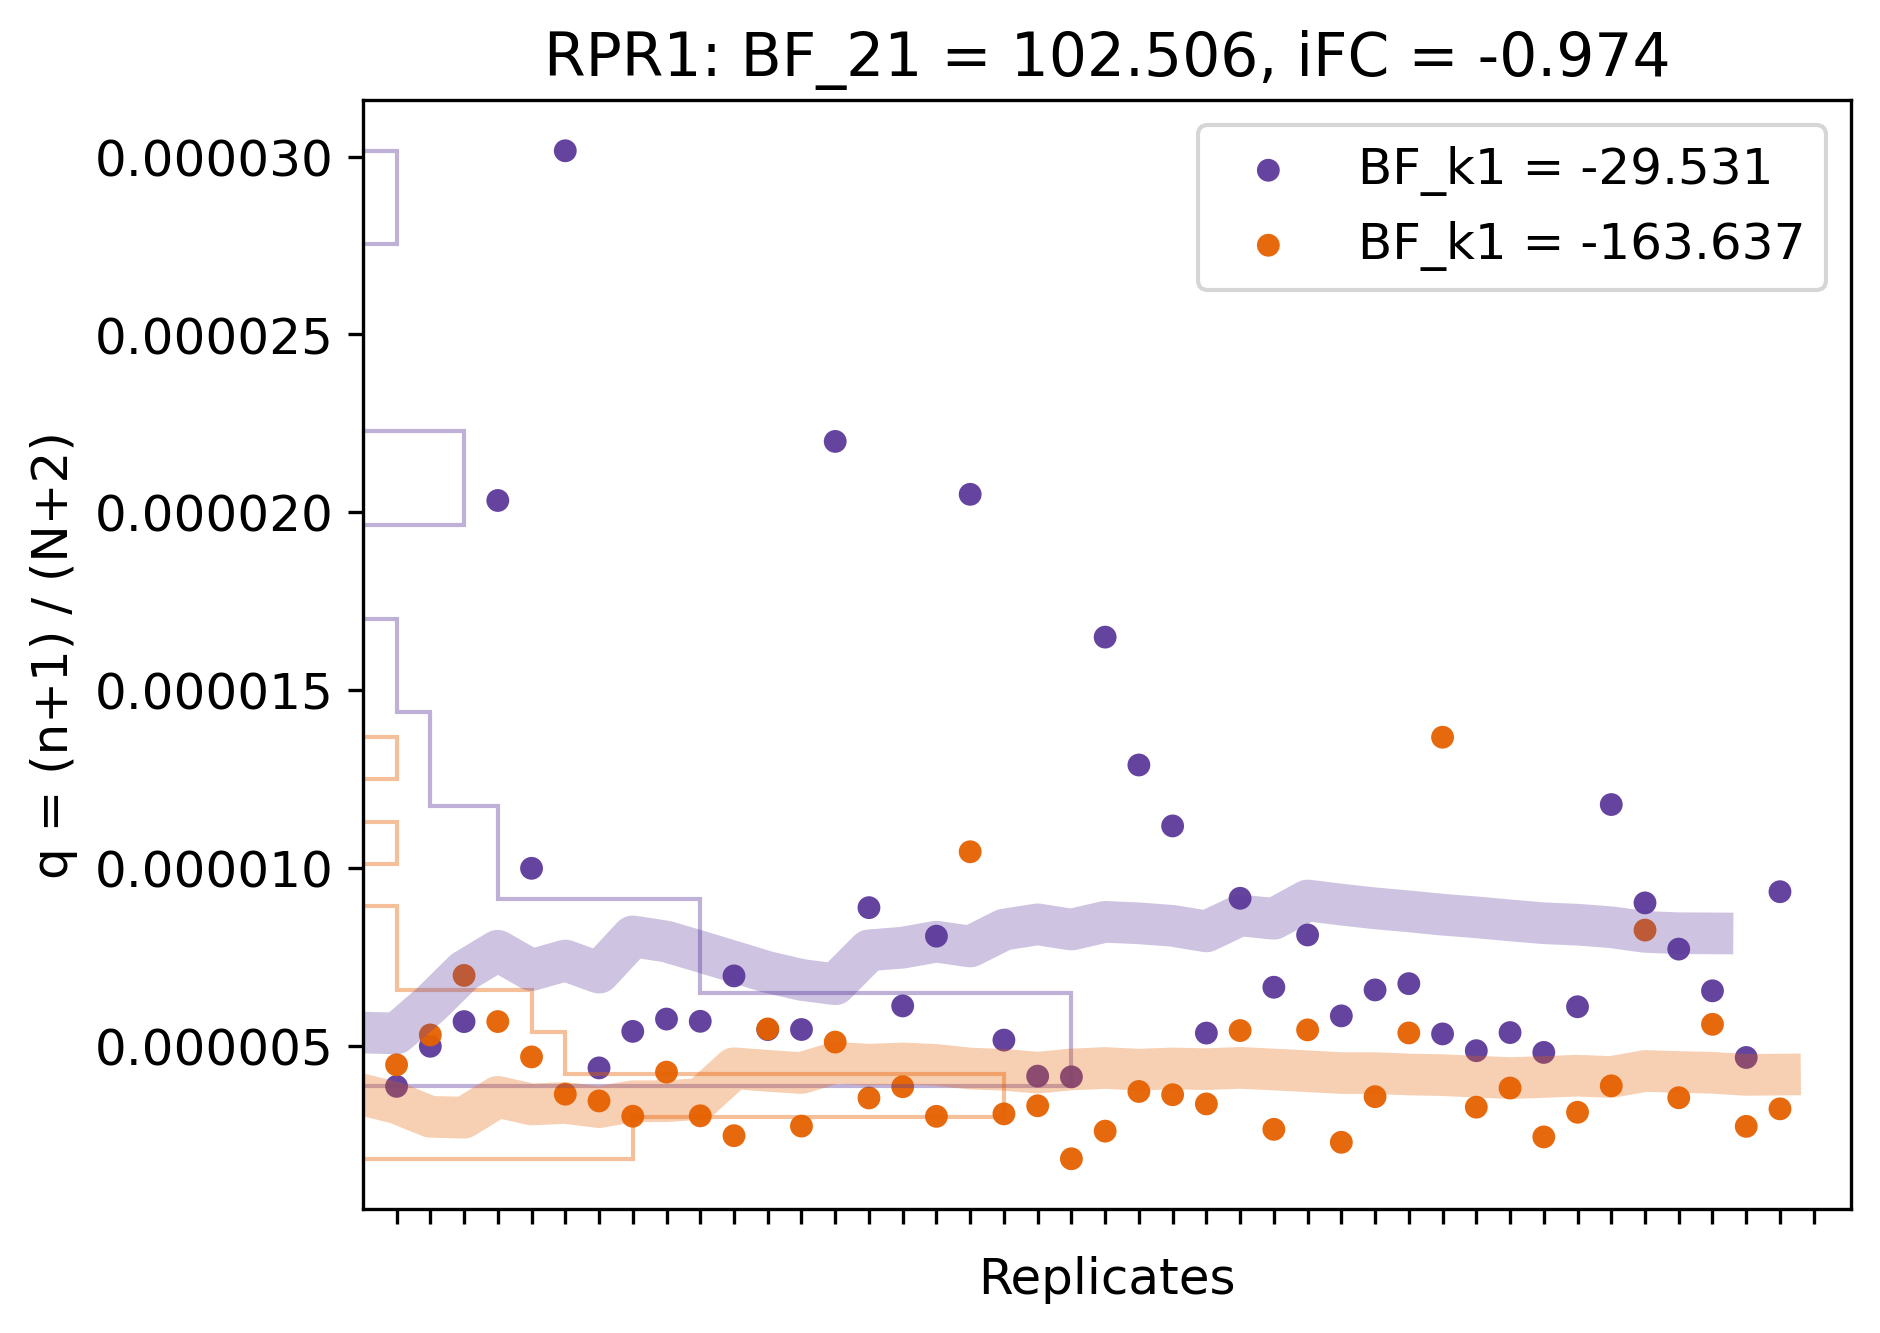

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
134,YAL063C-A,1,6,6,9,7,10,0,3,2,...,0,7,7,0,4,1,4,4,4,2


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
134,YAL063C-A,20,7,8,14,6,12,4,4,3,...,18,4,7,7,16,14,19,11,25,11


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
134,YAL063C-A,17.5168,1.355379,-233.605727,False,-236.430039,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


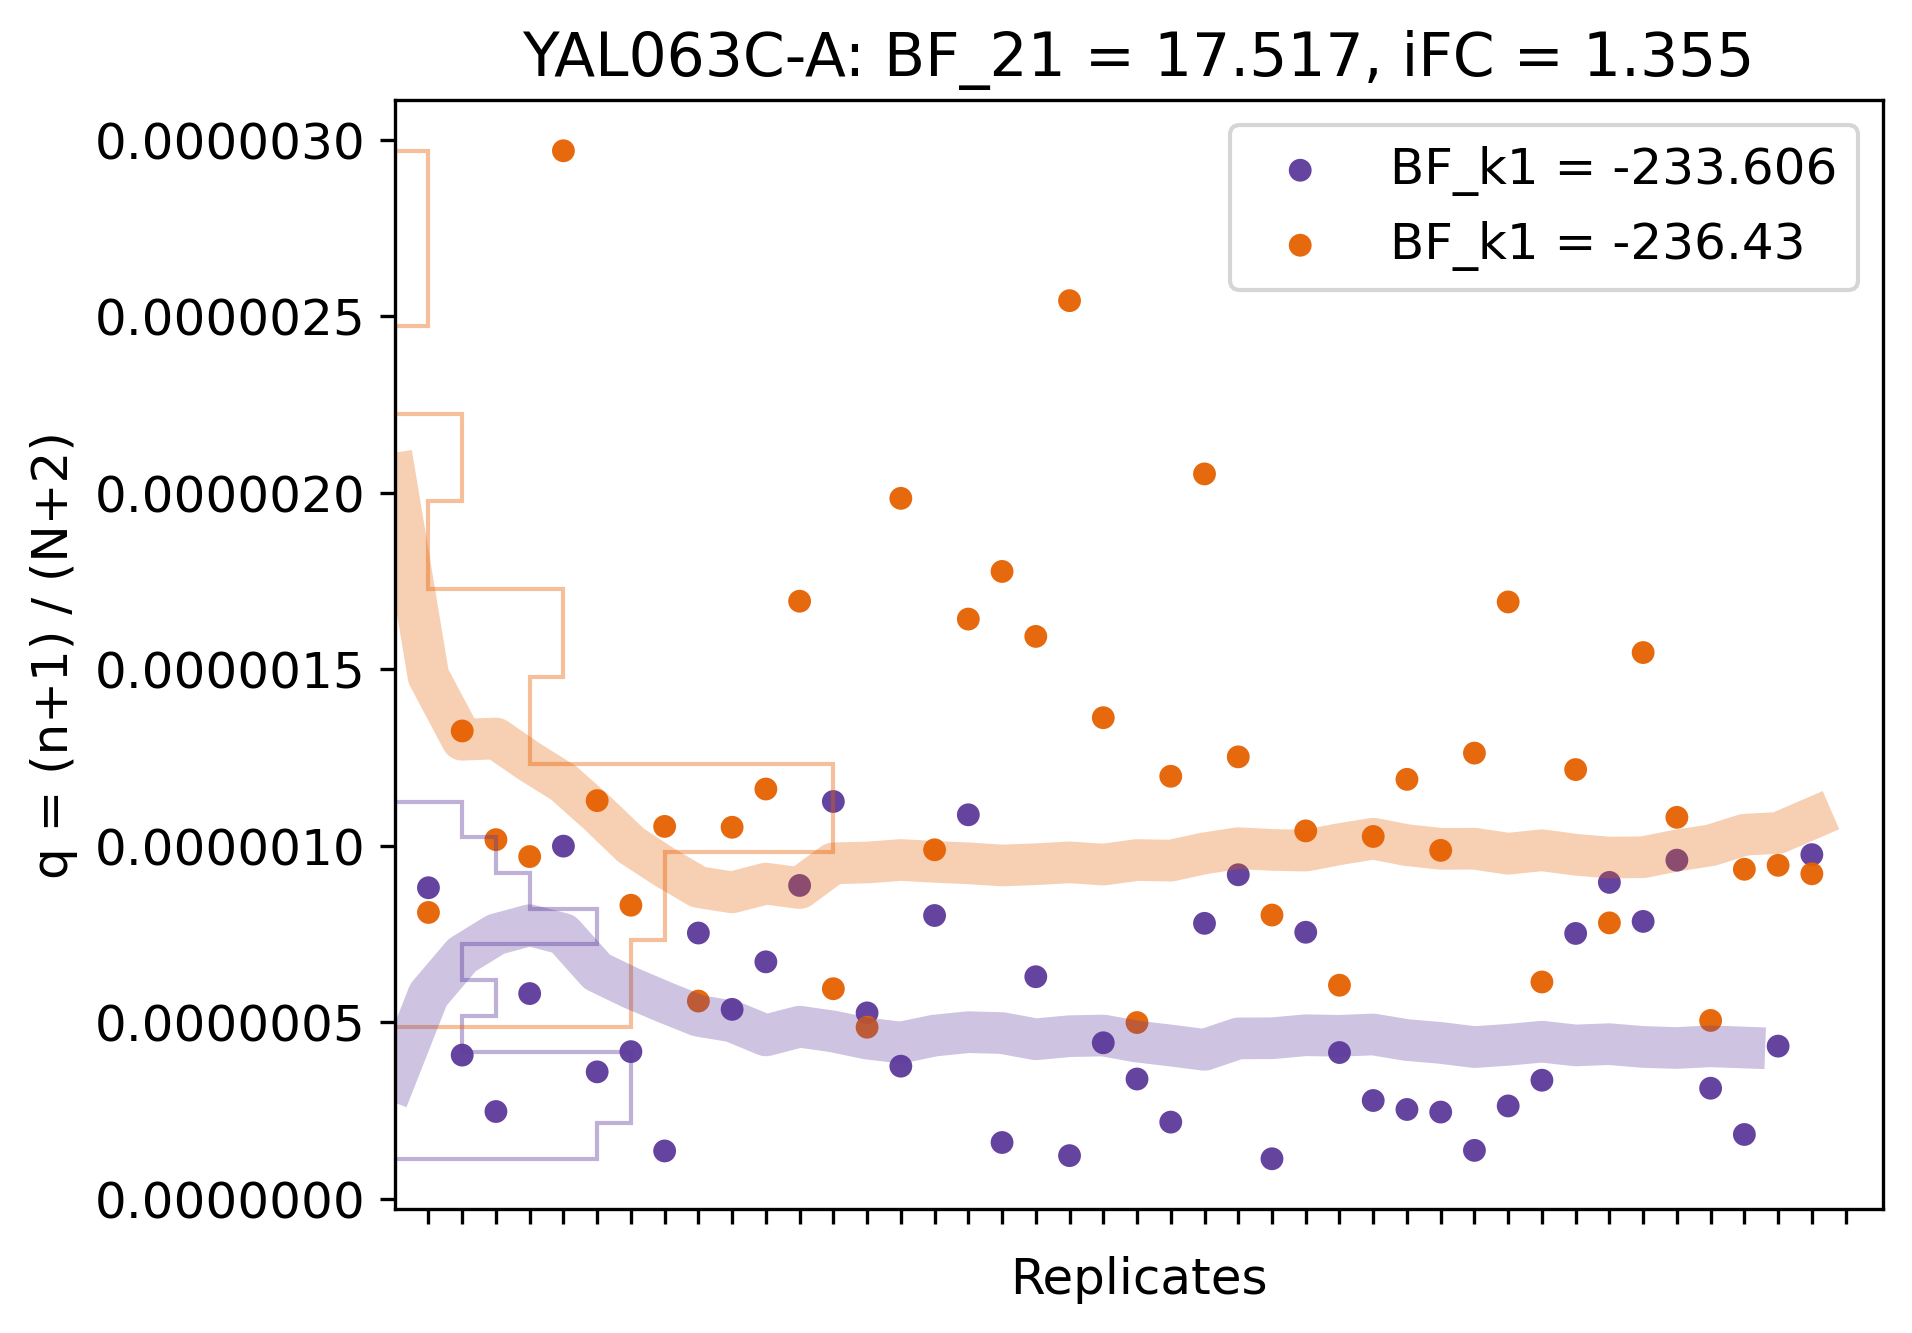

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
2606,YGR161W-C,262,317,255,453,250,447,249,517,368,...,269,525,304,296,302,357,355,275,400,390


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
2606,YGR161W-C,1045,879,684,1163,641,1181,1003,826,536,...,1466,870,1296,579,1000,1083,748,645,929,594


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
2606,YGR161W-C,2034.172394,1.302575,-85.422739,False,23.864628,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


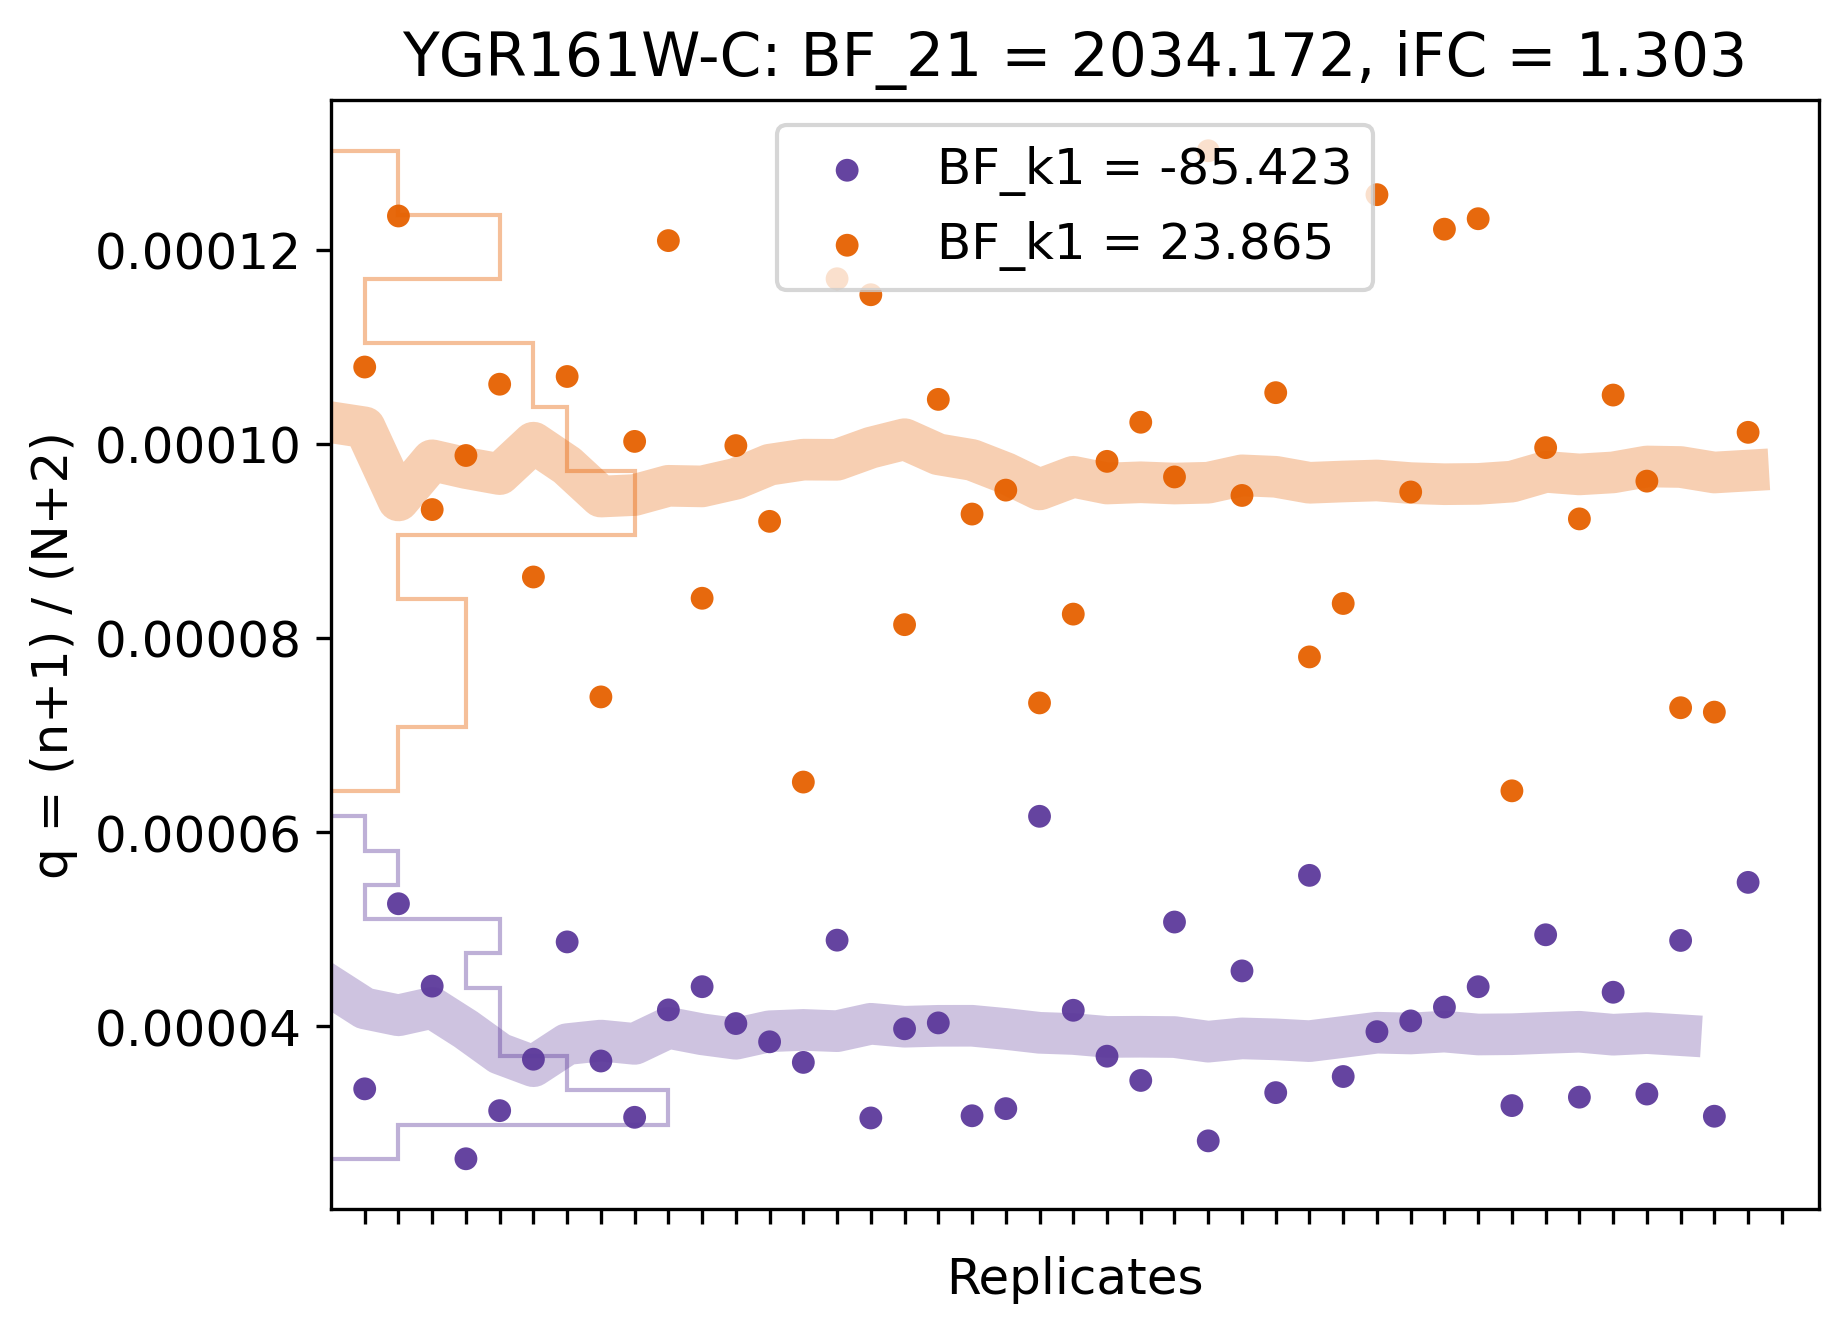

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
131,YAL061W,2114,1725,1485,3013,1544,2846,1915,2976,2486,...,1925,3438,1897,1600,2070,3089,2625,1375,2765,2397


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
131,YAL061W,771,767,557,704,555,886,607,513,445,...,944,526,805,489,662,575,511,491,557,443


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
131,YAL061W,9735.106916,-1.93853,556.998607,True,-115.775768,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


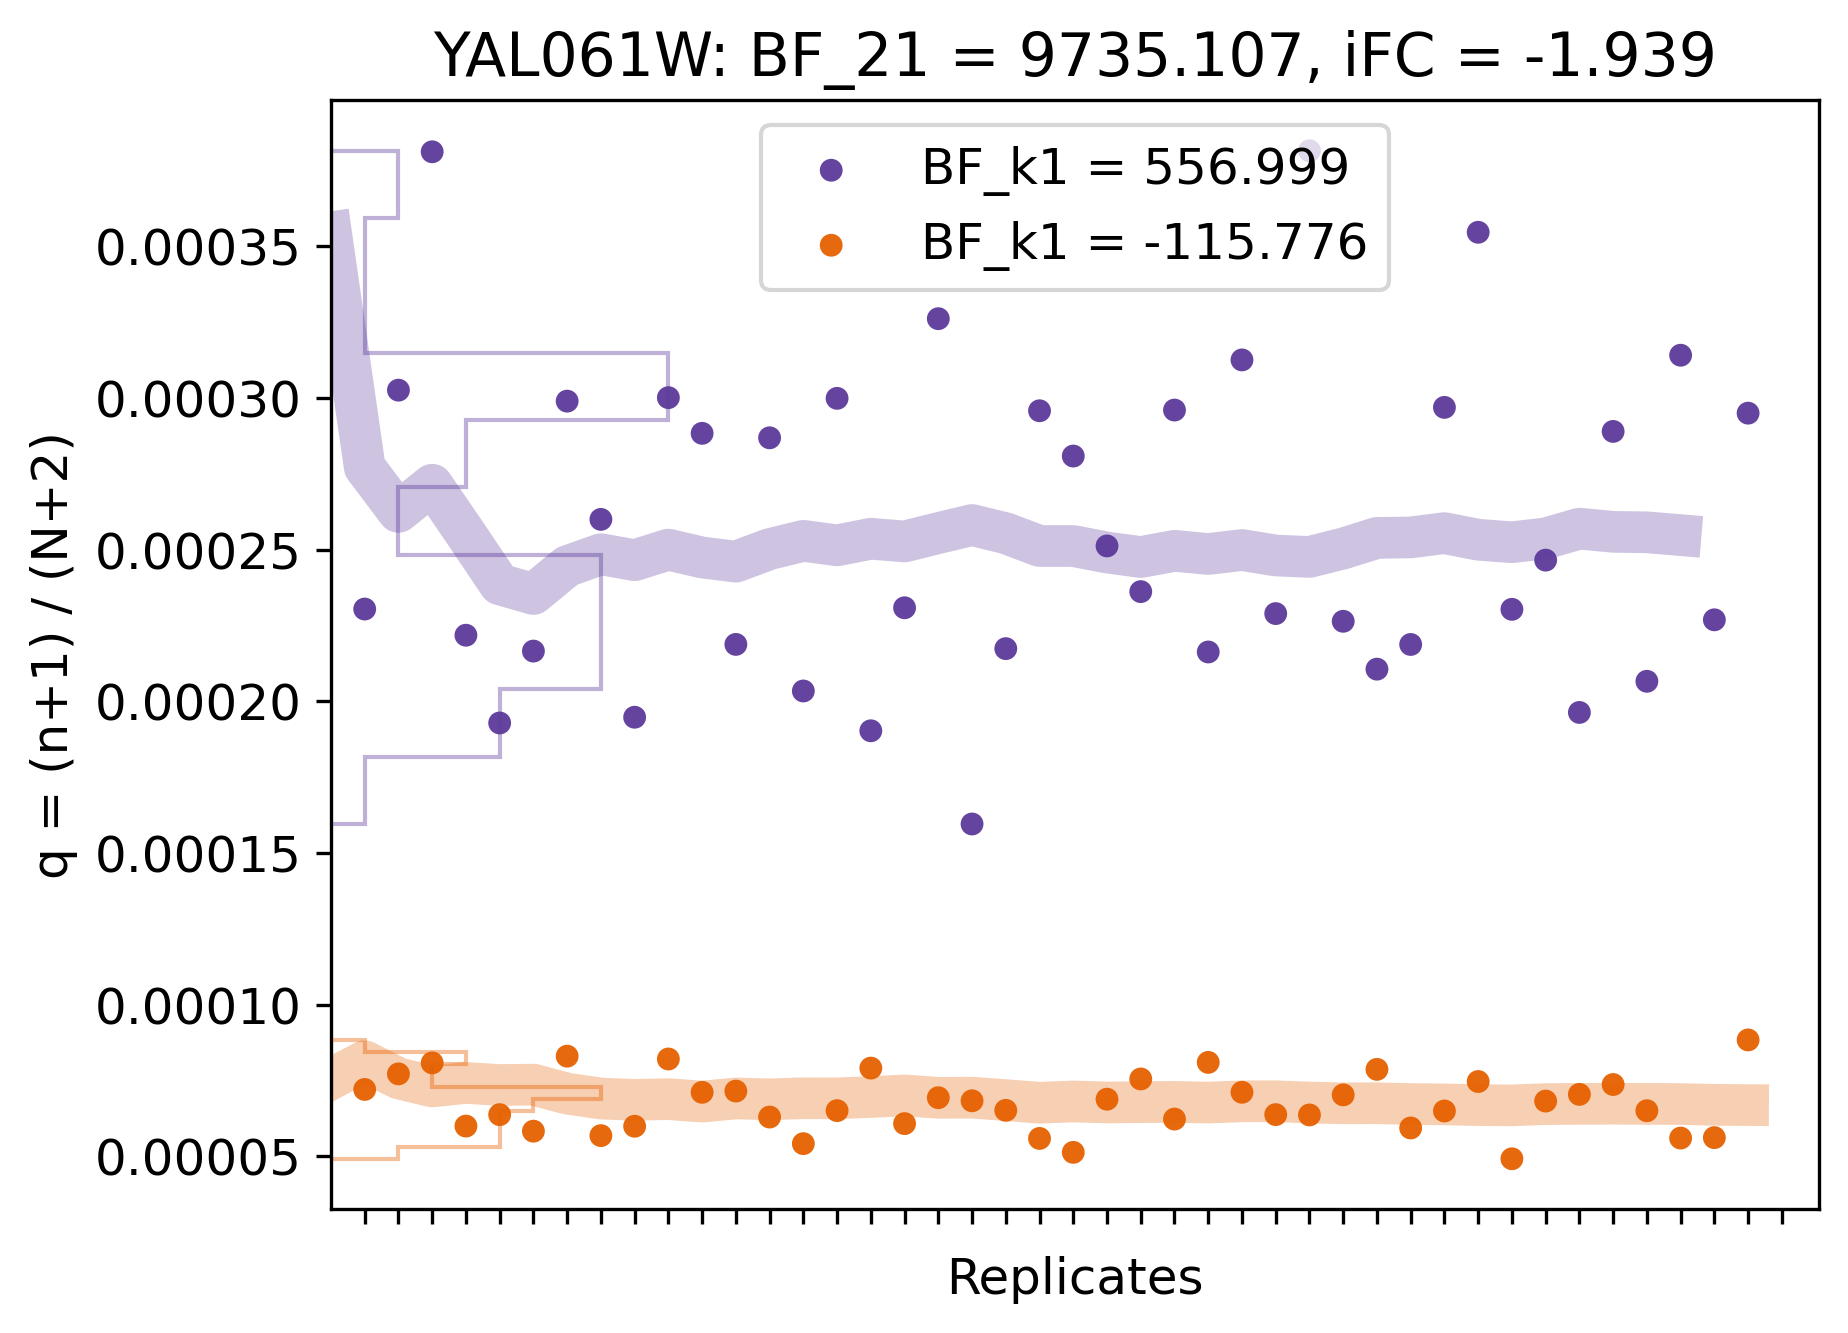

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,15S_rRNA,2,12,31,8,21,11,2,3,7,...,0,49,9,4,11,12,1,22,12,4


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,15S_rRNA,4,2,5,5,46,5,4,2,40,...,7,15,6,1,85,8,34,3,6,3


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
0,15S_rRNA,-3.710645,0.274047,-107.138056,False,53.627445,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant


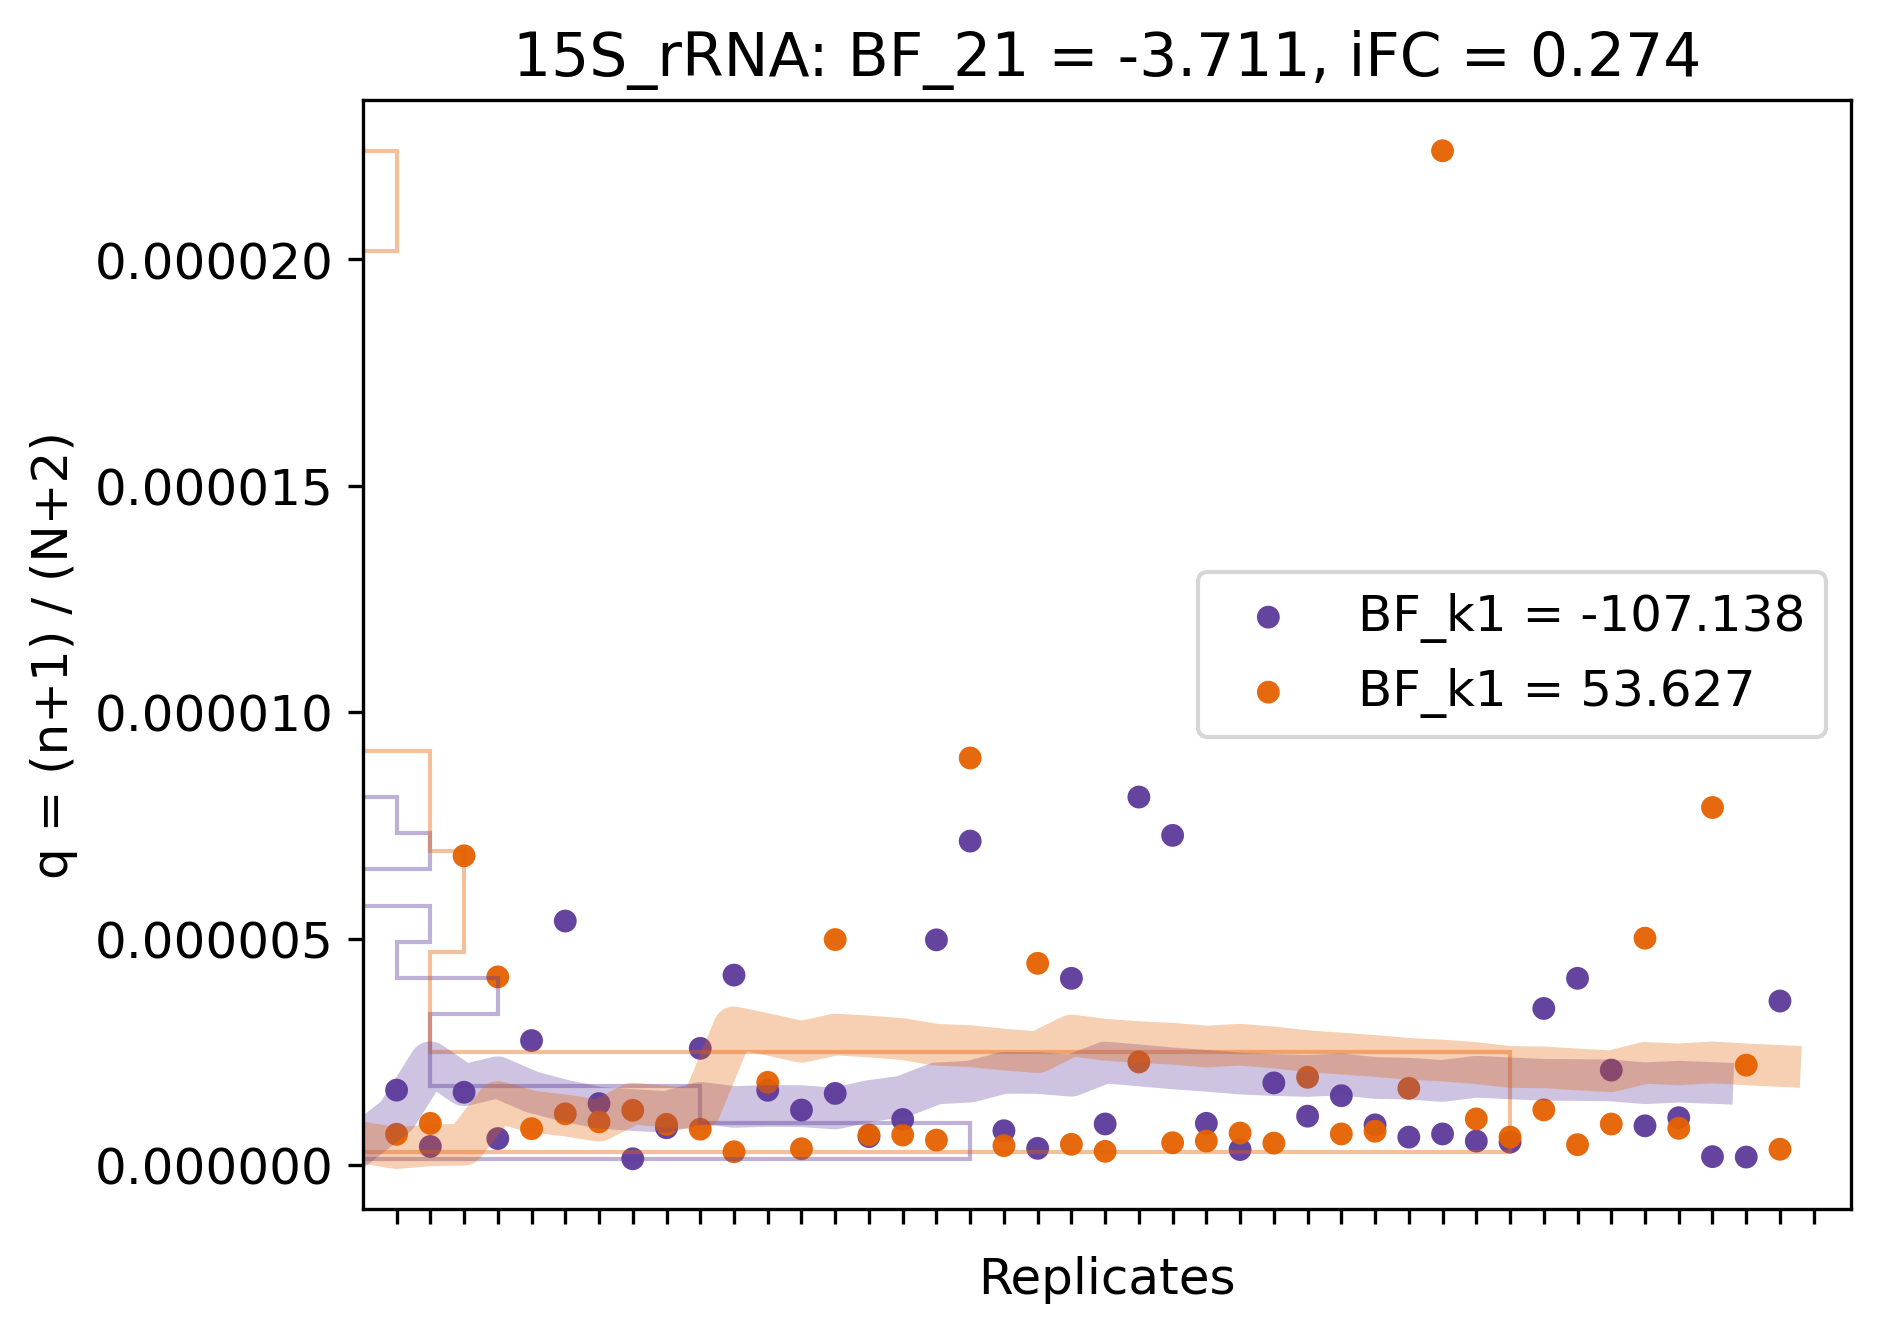

[None, None, None, None, None, None, None]

In [21]:
[q_plot([gene]) for gene in ['YAL016C-B', 'YDL062W', 'RPR1', 'YAL063C-A', 'YGR161W-C', 'YAL061W', '15S_rRNA']]